In [25]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

In [24]:
import os

print(os.getcwd())

c:\Users\kamila.a.salvini\Desktop\Kamila\IFSP - Análise de Dados\Exercícios


In [3]:
url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": -21.75,
    "longitude": -41.32,
    "start_date": "2025-01-01",
    "end_date": "2025-12-31",
    "daily": [
        "temperature_2m_mean",
        "temperature_2m_max",
        "temperature_2m_min",
        "precipitation_sum",
        "wind_speed_10m_max"
    ],
    "timezone": "America/Sao_Paulo"
}

response = requests.get(url, params=params)
response.raise_for_status()

dados = response.json()

print("Dados coletados com sucesso!")

Dados coletados com sucesso!


In [4]:
df = pd.DataFrame(dados["daily"])

df.head()

,time,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,wind_speed_10m_max
0,2025-01-01,25.1,30.9,22.1,12.9,18.7
1,2025-01-02,26.9,33.2,22.5,0.0,15.6
2,2025-01-03,27.2,31.8,23.7,0.4,19.0
3,2025-01-04,28.5,33.1,23.6,2.0,24.4
4,2025-01-05,26.1,31.1,22.4,6.2,21.3


In [5]:
df = df.rename(columns={
    "time": "Data",
    "temperature_2m_mean": "Temperatura_Media",
    "temperature_2m_max": "Temperatura_Maxima",
    "temperature_2m_min": "Temperatura_Minima",
    "precipitation_sum": "Precipitacao",
    "wind_speed_10m_max": "Vento_Maximo"
})

df.head()

,Data,Temperatura_Media,Temperatura_Maxima,Temperatura_Minima,Precipitacao,Vento_Maximo
0,2025-01-01,25.1,30.9,22.1,12.9,18.7
1,2025-01-02,26.9,33.2,22.5,0.0,15.6
2,2025-01-03,27.2,31.8,23.7,0.4,19.0
3,2025-01-04,28.5,33.1,23.6,2.0,24.4
4,2025-01-05,26.1,31.1,22.4,6.2,21.3


In [6]:
print("Quantidade de registros:", len(df))
print("\nInformações do dataset:")
df.info()

print("\nDados ausentes:")
print(df.isnull().sum())

print("\nRegistros duplicados:")
print(df.duplicated().sum())

Quantidade de registros: 365

Informações do dataset:
<class 'pandas.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Data                365 non-null    str    
 1   Temperatura_Media   365 non-null    float64
 2   Temperatura_Maxima  365 non-null    float64
 3   Temperatura_Minima  365 non-null    float64
 4   Precipitacao        365 non-null    float64
 5   Vento_Maximo        365 non-null    float64
dtypes: float64(5), str(1)
memory usage: 17.2 KB

Dados ausentes:
Data                  0
Temperatura_Media     0
Temperatura_Maxima    0
Temperatura_Minima    0
Precipitacao          0
Vento_Maximo          0
dtype: int64

Registros duplicados:
0


In [7]:
df["Data"] = pd.to_datetime(df["Data"])

df.head()

,Data,Temperatura_Media,Temperatura_Maxima,Temperatura_Minima,Precipitacao,Vento_Maximo
0,2025-01-01,25.1,30.9,22.1,12.9,18.7
1,2025-01-02,26.9,33.2,22.5,0.0,15.6
2,2025-01-03,27.2,31.8,23.7,0.4,19.0
3,2025-01-04,28.5,33.1,23.6,2.0,24.4
4,2025-01-05,26.1,31.1,22.4,6.2,21.3


In [8]:
df.describe()

,Data,Temperatura_Media,Temperatura_Maxima,Temperatura_Minima,Precipitacao,Vento_Maximo
count,365,365.000000,365.000000,365.000000,365.000000,365.000000
mean,2025-07-02 00:00:00,24.207397,29.793699,20.098630,2.359726,18.271781
min,2025-01-01 00:00:00,18.000000,20.800000,12.200000,0.000000,8.900000
25%,2025-04-02 00:00:00,21.900000,26.600000,18.000000,0.000000,15.200000
50%,2025-07-02 00:00:00,23.800000,29.200000,20.200000,0.400000,18.000000
75%,2025-10-01 00:00:00,26.700000,33.200000,22.500000,2.000000,21.100000
max,2025-12-31 00:00:00,31.600000,40.100000,25.400000,29.100000,32.300000
std,NaN,3.124491,4.111701,3.062171,4.688511,4.395414


In [9]:
print("Temperatura média do período:",
      round(df["Temperatura_Media"].mean(), 2), "°C")

print("Maior temperatura:",
      round(df["Temperatura_Maxima"].max(), 2), "°C")

print("Menor temperatura:",
      round(df["Temperatura_Minima"].min(), 2), "°C")

print("Precipitação total:",
      round(df["Precipitacao"].sum(), 2), "mm")

print("Maior velocidade do vento:",
      round(df["Vento_Maximo"].max(), 2), "km/h")

Temperatura média do período: 24.21 °C
Maior temperatura: 40.1 °C
Menor temperatura: 12.2 °C
Precipitação total: 861.3 mm
Maior velocidade do vento: 32.3 km/h


In [10]:
dia_quente = df.loc[df["Temperatura_Maxima"].idxmax()]

print("Dia mais quente:")
print("Data:", dia_quente["Data"].strftime("%d/%m/%Y"))
print("Temperatura:", dia_quente["Temperatura_Maxima"], "°C")

Dia mais quente:
Data: 21/01/2025
Temperatura: 40.1 °C


In [11]:
dia_frio = df.loc[df["Temperatura_Minima"].idxmin()]

print("Dia mais frio:")
print("Data:", dia_frio["Data"].strftime("%d/%m/%Y"))
print("Temperatura:", dia_frio["Temperatura_Minima"], "°C")

Dia mais frio:
Data: 28/09/2025
Temperatura: 12.2 °C


In [12]:
dia_chuvoso = df.loc[df["Precipitacao"].idxmax()]

print("Dia mais chuvoso:")
print("Data:", dia_chuvoso["Data"].strftime("%d/%m/%Y"))
print("Precipitação:", dia_chuvoso["Precipitacao"], "mm")

Dia mais chuvoso:
Data: 26/07/2025
Precipitação: 29.1 mm


In [13]:
df["Mes"] = df["Data"].dt.month

df.head()

,Data,Temperatura_Media,Temperatura_Maxima,Temperatura_Minima,Precipitacao,Vento_Maximo,Mes
0,2025-01-01,25.1,30.9,22.1,12.9,18.7,1
1,2025-01-02,26.9,33.2,22.5,0.0,15.6,1
2,2025-01-03,27.2,31.8,23.7,0.4,19.0,1
3,2025-01-04,28.5,33.1,23.6,2.0,24.4,1
4,2025-01-05,26.1,31.1,22.4,6.2,21.3,1


In [14]:
temperatura_mensal = df.groupby("Mes")["Temperatura_Media"].mean()

print(temperatura_mensal)

Mes
1     27.358065
2     29.128571
3     27.054839
4     24.573333
5     23.009677
6     21.880000
7     20.309677
8     21.141935
9     22.340000
10    23.203226
11    24.313333
12    26.532258
Name: Temperatura_Media, dtype: float64


In [15]:
mes_mais_quente = temperatura_mensal.idxmax()
mes_mais_frio = temperatura_mensal.idxmin()

print("Mês mais quente:", mes_mais_quente)
print("Mês mais frio:", mes_mais_frio)

Mês mais quente: 2
Mês mais frio: 7


In [16]:
precipitacao_mensal = df.groupby("Mes")["Precipitacao"].sum()

print(precipitacao_mensal)

Mes
1      95.2
2      17.4
3     108.6
4     101.3
5      28.5
6      26.8
7      48.6
8      46.3
9      48.1
10    106.2
11     65.8
12    168.5
Name: Precipitacao, dtype: float64


In [17]:
mes_mais_chuvoso = precipitacao_mensal.idxmax()

print("Mês mais chuvoso:", mes_mais_chuvoso)
print(
    "Precipitação:",
    round(precipitacao_mensal.max(), 2),
    "mm"
)

Mês mais chuvoso: 12
Precipitação: 168.5 mm


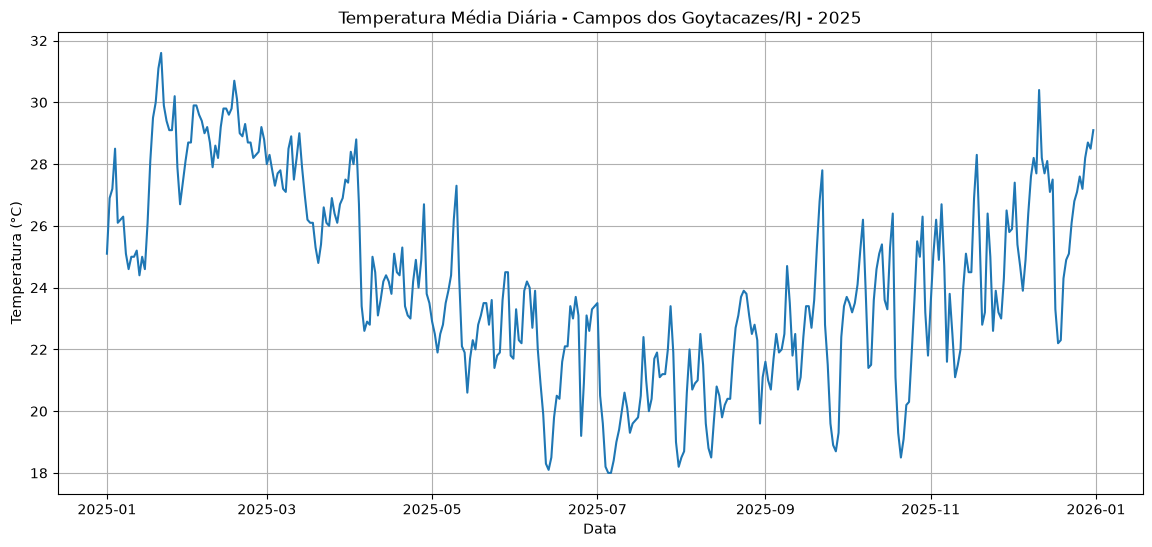

In [26]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["Data"],
    df["Temperatura_Media"]
)

plt.title("Temperatura Média Diária - Campos dos Goytacazes/RJ - 2025")
plt.xlabel("Data")
plt.ylabel("Temperatura (°C)")

plt.grid()

plt.savefig(
    "Imagens/temperatura_diaria.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

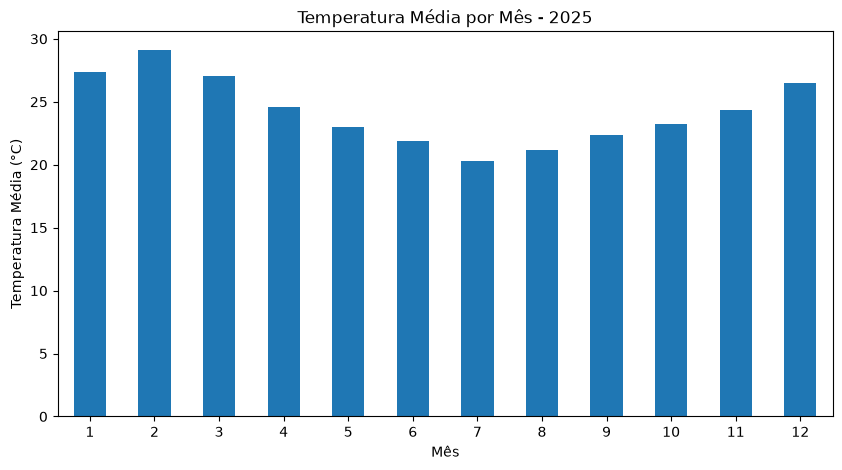

In [27]:
plt.figure(figsize=(10, 5))

temperatura_mensal.plot(kind="bar")

plt.title("Temperatura Média por Mês - 2025")
plt.xlabel("Mês")
plt.ylabel("Temperatura Média (°C)")
plt.xticks(rotation=0)

plt.savefig(
    "Imagens/temperatura_mensal.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

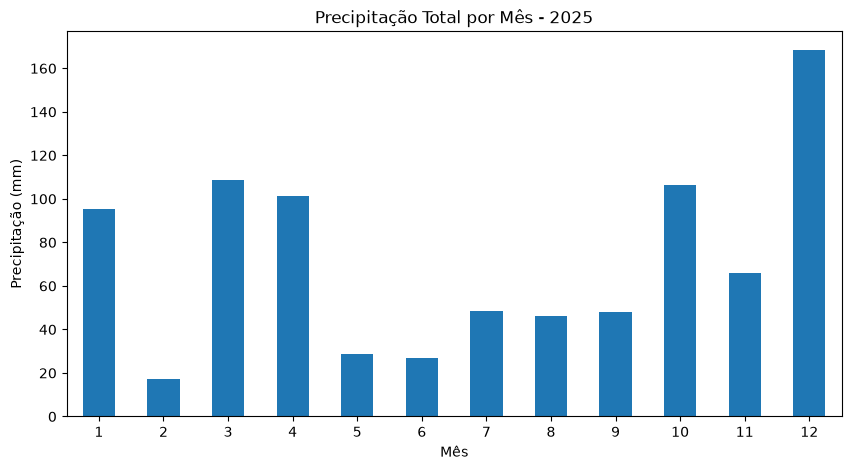

In [28]:
plt.figure(figsize=(10, 5))

precipitacao_mensal.plot(kind="bar")

plt.title("Precipitação Total por Mês - 2025")
plt.xlabel("Mês")
plt.ylabel("Precipitação (mm)")
plt.xticks(rotation=0)

plt.savefig(
    "Imagens/precipitacao_mensal.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [21]:
print("RESUMO DA ANÁLISE")
print("-" * 40)

print(
    "Temperatura média:",
    round(df["Temperatura_Media"].mean(), 2),
    "°C"
)

print(
    "Maior temperatura:",
    round(df["Temperatura_Maxima"].max(), 2),
    "°C"
)

print(
    "Menor temperatura:",
    round(df["Temperatura_Minima"].min(), 2),
    "°C"
)

print(
    "Precipitação total:",
    round(df["Precipitacao"].sum(), 2),
    "mm"
)

print(
    "Mês mais quente:",
    mes_mais_quente
)

print(
    "Mês mais frio:",
    mes_mais_frio
)

print(
    "Mês mais chuvoso:",
    mes_mais_chuvoso
)

RESUMO DA ANÁLISE
----------------------------------------
Temperatura média: 24.21 °C
Maior temperatura: 40.1 °C
Menor temperatura: 12.2 °C
Precipitação total: 861.3 mm
Mês mais quente: 2
Mês mais frio: 7
Mês mais chuvoso: 12


In [22]:
df.to_csv(
    "dados_climaticos_campos_2025.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Arquivo salvo com sucesso!")

Arquivo salvo com sucesso!


In [23]:
import os

tamanho_bytes = os.path.getsize("dados_climaticos_campos_2025.csv")
tamanho_kb = tamanho_bytes / 1024

print(f"Tamanho do arquivo: {tamanho_kb:.2f} KB")

Tamanho do arquivo: 13.75 KB
